# 04 — Change hotspots, uncertainty & the Siachen centreline
Turns velocity maps into *intelligence*:
1. **Uncertainty** — relative error of ITS_LIVE speeds; NISAR confidence from how many pairs/geometries measured each pixel.
2. **Significant change** — a pixel counts as speeding up / slowing down only if the 2017–22 trend is ≥ 2 standard errors from zero
   **and** the 2017→2022 change exceeds 2× its measurement uncertainty.
3. **Hotspots** — connected areas of significant change ≥ 0.25 km², ranked.
4. **Centreline** — least-cost path through the fastest ice from Siachen's upper basin to its terminus, used for speed profiles.

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_DIR = Path(r"D:\Pakistan Glacier Intelligence Explorer")
sys.path.insert(0, str(PROJECT_DIR / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from pyproj import Transformer
from pgie.common import PROCESSED_DIR, RESULTS_DIR, FIGURES_DIR, read_tif, save_tif
from pgie.analysis import trend_with_stderr, significant_change, label_regions, least_cost_path

ITS = PROCESSED_DIR / "its_live_siachen"
YEARS = list(range(2017, 2023))
load = lambda y, v: read_tif(ITS / f"siachen_{y}_{v}.tif")[0]
_, T, CRS = read_tif(ITS / "siachen_2017_v.tif")
v = np.stack([load(y, "v") for y in YEARS]); verr = np.stack([load(y, "v_error") for y in YEARS]); cnt = np.stack([load(y, "count") for y in YEARS])
good = np.isfinite(v) & np.isfinite(verr) & (cnt >= 5) & ((verr <= 20) | (verr <= 0.25 * v)) & (v < 1500)
v = np.where(good, v, np.nan); verr = np.where(good, verr, np.nan)
v_med = np.nanmedian(v, 0); ice = v_med >= 15
PIX_KM2 = abs(T.a * T.e) / 1e6
to_ll = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 9})
print("ice pixels:", int(ice.sum()), f"({ice.sum()*PIX_KM2:.0f} km²)")

ice pixels: 53949 (777 km²)


## 1. Uncertainty

In [2]:
rel_err = np.nanmedian(verr / v, 0) * 100           # % relative error, median over years
rel_err = np.where(ice, rel_err, np.nan)
rel_class = np.select([rel_err <= 10, rel_err <= 25], [3, 2], default=1).astype("float32")   # 3 high, 2 medium, 1 low
rel_class[~np.isfinite(rel_err)] = np.nan
save_tif(ITS / "siachen_relative_error_pct.tif", rel_err, T, CRS)
save_tif(ITS / "siachen_reliability_class.tif", rel_class, T, CRS)
share = {k: round(100 * np.nanmean(rel_class[ice] == c), 1) for k, c in [("high (≤10%)", 3), ("medium (10–25%)", 2), ("low (>25%)", 1)]}
print("ITS_LIVE reliability of ice pixels:", share)

ITS_LIVE reliability of ice pixels: {'high (≤10%)': np.float64(85.6), 'medium (10–25%)': np.float64(12.8), 'low (>25%)': np.float64(1.6)}


## 2. Significant change 2017 → 2022

In [3]:
slope, se, n = trend_with_stderr(v, YEARS)
dv = v[-1] - v[0]
dv_err = np.sqrt(verr[-1] ** 2 + verr[0] ** 2)
sig = significant_change(slope, se, dv, dv_err)
sig = np.where(ice, sig, np.nan)
save_tif(ITS / "siachen_significant_change.tif", sig, T, CRS)
save_tif(ITS / "siachen_trend_stderr.tif", np.where(ice, se, np.nan), T, CRS)
tbl = pd.Series({"significant speed-up": np.nanmean(sig[ice] == 1) * 100, "significant slow-down": np.nanmean(sig[ice] == -1) * 100,
                 "no significant change": np.nanmean(sig[ice] == 0) * 100}).round(1)
print("% of glacier ice:"); print(tbl.to_string())

% of glacier ice:
significant speed-up     21.0
significant slow-down     5.0
no significant change    72.9


## 3. Hotspots (connected significant-change areas ≥ 0.25 km²)

In [4]:
MIN_PX = int(np.ceil(0.25 / PIX_KM2))
rows, hot_mask = [], np.zeros(sig.shape, "float32") * np.nan
for sign, kind in [(1, "speed-up"), (-1, "slow-down")]:
    labels, nlab = label_regions(sig == sign)
    for k in range(1, nlab + 1):
        m = labels == k
        if m.sum() < MIN_PX:
            continue
        rr, cc = np.nonzero(m)
        i = np.argmax(np.abs(np.where(m, dv, 0)))               # most-changed pixel = map anchor
        r_i, c_i = np.unravel_index(i, m.shape)
        lon, lat = to_ll.transform(T.c + (c_i + .5) * T.a, T.f + (r_i + .5) * T.e)
        v17, v22 = np.nanmedian(v[0][m]), np.nanmedian(v[-1][m])
        rows.append({"kind": kind, "area_km2": round(m.sum() * PIX_KM2, 2), "lon": round(lon, 4), "lat": round(lat, 4),
                     "median_trend_m_yr2": round(float(np.nanmedian(slope[m])), 1),
                     "speed_2017": round(float(v17), 1), "speed_2022": round(float(v22), 1),
                     "change_pct": round(float(100 * (v22 - v17) / v17), 0) if v17 > 0 else None,
                     "max_change_m_yr": round(float(dv[r_i, c_i]), 1)})
        hot_mask[m] = sign
hot = pd.DataFrame(rows).sort_values("area_km2", ascending=False).reset_index(drop=True)
hot.insert(0, "rank", hot.index + 1)
hot.to_csv(RESULTS_DIR / "change_hotspots.csv", index=False)
save_tif(ITS / "siachen_hotspots.tif", hot_mask, T, CRS)
print(f"{len(hot)} hotspots ({(hot.kind=='speed-up').sum()} speed-up, {(hot.kind=='slow-down').sum()} slow-down)")
hot.head(12)

84 hotspots (78 speed-up, 6 slow-down)


,rank,kind,area_km2,lon,lat,median_trend_m_yr2,speed_2017,speed_2022,change_pct,max_change_m_yr
0,1,speed-up,17.60,76.9491,35.5320,10.0,116.9,172.9,48.0,93.3
1,2,speed-up,16.66,76.9938,35.6917,6.3,100.8,129.0,28.0,100.3
2,3,slow-down,15.58,77.1879,35.6377,-15.1,107.7,18.1,-83.0,-128.3
3,4,speed-up,9.76,77.0991,35.5034,2.4,97.7,107.0,10.0,40.6
4,5,slow-down,8.06,76.7068,35.4810,-7.7,104.5,67.6,-35.0,-71.1
5,6,speed-up,5.86,77.3053,35.2657,14.5,39.5,131.4,233.0,199.8
6,7,speed-up,4.25,77.1754,35.2300,3.8,95.9,110.4,15.0,26.1
7,8,speed-up,3.23,77.3021,35.5807,3.3,22.7,41.9,84.0,32.2
8,9,speed-up,3.07,76.9015,35.3330,3.8,62.0,79.3,28.0,46.1
9,10,speed-up,2.92,77.3517,35.4678,6.1,88.8,124.9,41.0,52.7


## 4. Siachen centreline (fastest-ice least-cost path, upper basin → terminus)

In [5]:
to_xy = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
def rc_of(lon, lat):
    x, y = to_xy.transform(lon, lat)
    return int((T.f - y) / -T.e), int((x - T.c) / T.a)
def snap(lon, lat, radius=12):
    r, c = rc_of(lon, lat)
    win = np.where(ice, v_med, -1)[r - radius:r + radius + 1, c - radius:c + radius + 1]
    dr, dc = np.unravel_index(np.nanargmax(win), win.shape)
    return r - radius + dr, c - radius + dc

# terminus = Siachen snout (southernmost pixel of the main-trunk ice body, found from the data); head = upper NW basin
term = snap(77.192, 35.205, radius=2); head = snap(76.84, 35.63)   # snout near the Nubra valley head
cost = np.where(ice, 1.0 / (np.nan_to_num(v_med) + 5.0), np.inf)
path = least_cost_path(cost, head, term)
xs = [T.c + (c + .5) * T.a for r, c in path]; ys = [T.f + (r + .5) * T.e for r, c in path]
lons, lats = to_ll.transform(xs, ys)
from pyproj import Geod   # true ground distance (the equal-area grid distorts lengths by ~8% at this latitude)
_, _, step = Geod(ellps="WGS84").inv(lons[:-1], lats[:-1], lons[1:], lats[1:])
dist_km = np.concatenate([[0], np.cumsum(step)]) / 1000
print(f"centreline: {len(path)} px, length {dist_km[-1]:.1f} km")
line = {"type": "Feature", "properties": {"name": "Siachen main trunk", "length_km": round(dist_km[-1], 1)},
        "geometry": {"type": "LineString", "coordinates": [[round(a, 5), round(b, 5)] for a, b in list(zip(lons, lats))[::2]]}}
(PROCESSED_DIR / "siachen_centreline.geojson").write_text(json.dumps(line))

prof = pd.DataFrame({"distance_km": dist_km, **{str(y): [v[i][r, c] for r, c in path] for i, y in enumerate(YEARS)}})
prof.to_csv(RESULTS_DIR / "siachen_centreline_profile.csv", index=False)

centreline: 422 px, length 67.1 km


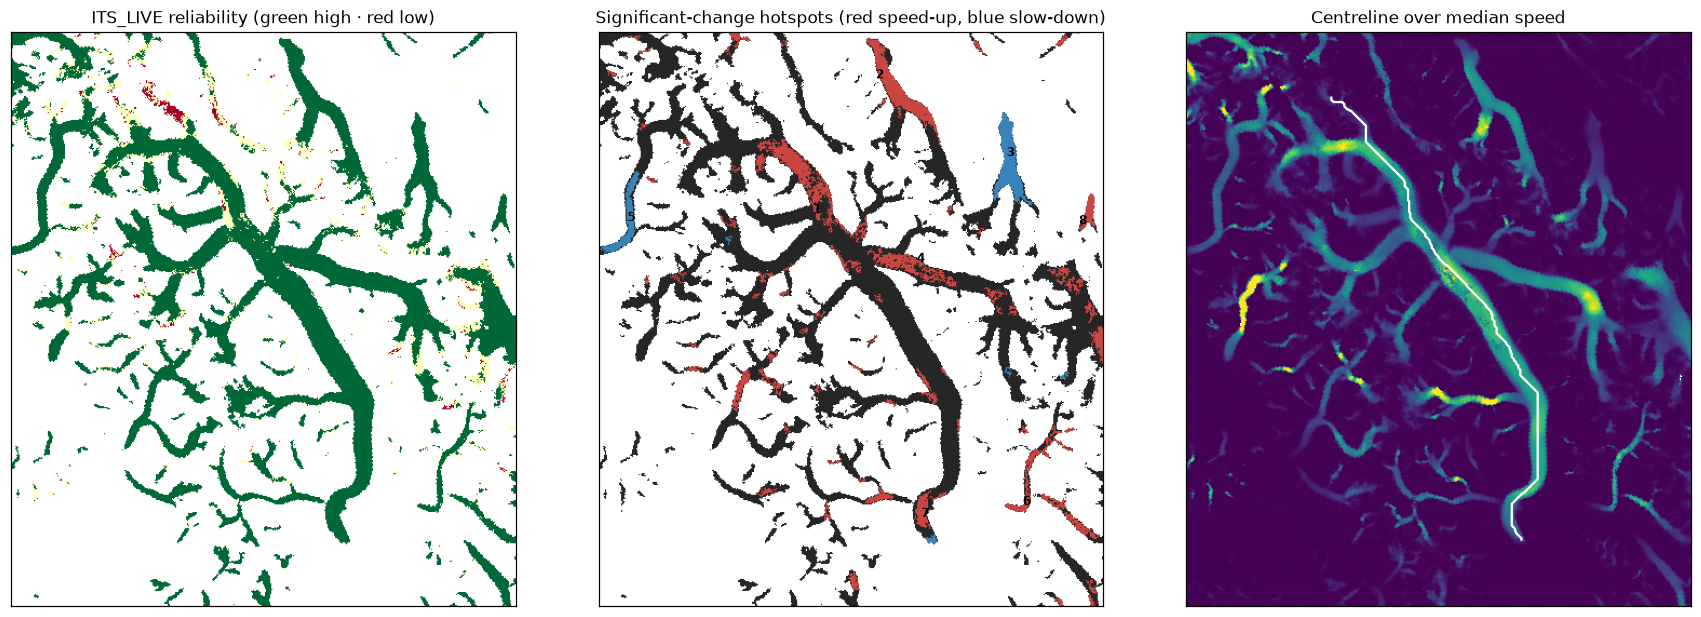

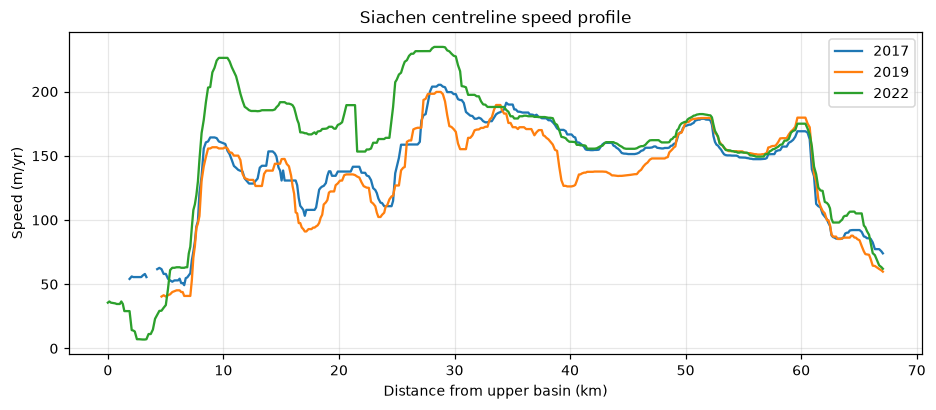

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)
im = axes[0].imshow(rel_class, cmap="RdYlGn", vmin=1, vmax=3); axes[0].set_title("ITS_LIVE reliability (green high · red low)")
lim = 1
axes[1].imshow(np.where(ice, 0.15, np.nan), cmap="gray", vmin=0, vmax=1)
axes[1].imshow(hot_mask, cmap="RdBu_r", vmin=-1.5, vmax=1.5); axes[1].set_title("Significant-change hotspots (red speed-up, blue slow-down)")
for _, h in hot.head(8).iterrows():
    r, c = rc_of(h.lon, h.lat); axes[1].annotate(str(h["rank"]), (c, r), color="k", fontsize=8, weight="bold", ha="center")
axes[2].imshow(v_med, cmap="viridis", vmin=0, vmax=np.nanpercentile(v_med[ice], 99))
axes[2].plot([c for r, c in path], [r for r, c in path], "w-", lw=1.5); axes[2].set_title("Centreline over median speed")
for a in axes: a.set_xticks([]); a.set_yticks([])
fig.savefig(FIGURES_DIR / "hotspots_reliability_centreline.png"); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.8))
for y in (2017, 2019, 2022):
    ax.plot(prof.distance_km, prof[str(y)].rolling(9, center=True, min_periods=3).median(), label=str(y))
ax.set_xlabel("Distance from upper basin (km)"); ax.set_ylabel("Speed (m/yr)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Siachen centreline speed profile")
fig.savefig(FIGURES_DIR / "centreline_profile.png"); plt.show()